# Analyse des ventes de janvier à septembre 2025

Ce notebook s'appuie sur le paquet `rapport_ventes` du projet : le chargement, les jointures et les calculs sont faits par les mêmes fonctions que la commande `rapport-ventes`. Il sert à explorer et à commenter les résultats.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

from rapport_ventes import graphiques
from rapport_ventes.chargement import charger_reference, charger_ventes
from rapport_ventes.config import charger_config
from rapport_ventes.indicateurs import enrichir, indicateurs_mois_region
from rapport_ventes.rapport import chiffres_cles

RACINE = Path("..")
config = charger_config(RACINE / "config.yaml")
donnees = config["donnees"]

ventes = charger_ventes(RACINE / donnees["ventes"])
produits = charger_reference(RACINE / donnees["produits"], "id_produit")
regions = charger_reference(RACINE / donnees["regions"], "code_region")

df = enrichir(ventes, produits, regions)
indicateurs = indicateurs_mois_region(df)

17 ventes de produits hors catalogue : P17


## 1. Vue d'ensemble

In [2]:
chiffres_cles(df)

ChiffresCles(ca=409501.58999999997, nb_commandes=2182, panier_moyen=187.6725893675527, debut=Timestamp('2025-01-01 00:00:00'), fin=Timestamp('2025-09-30 00:00:00'))

Près de 410 000 € de chiffre d'affaires sur neuf mois, pour 2 182 commandes et un panier moyen de 188 €.

## 2. Une activité très saisonnière

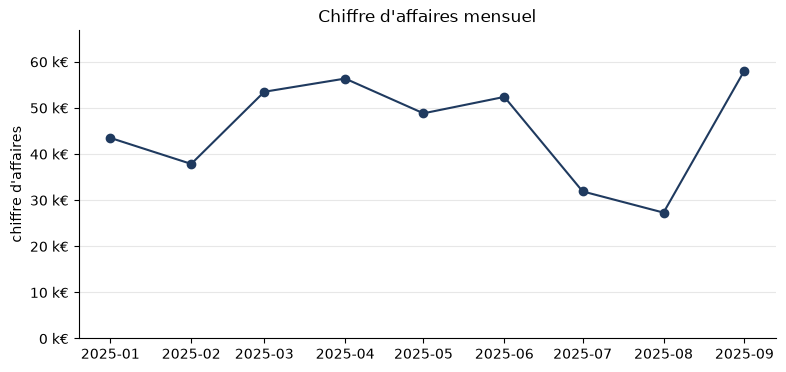

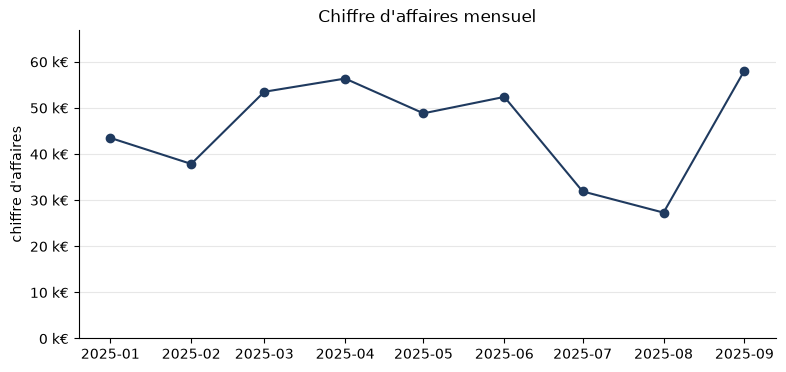

In [3]:
graphiques.ca_mensuel(indicateurs)

L'activité oscille entre 38 et 56 k€ par mois au premier semestre, chute de moitié en juillet et août, puis repart fortement en septembre, meilleur mois depuis janvier.

## 3. Une région porte l'activité

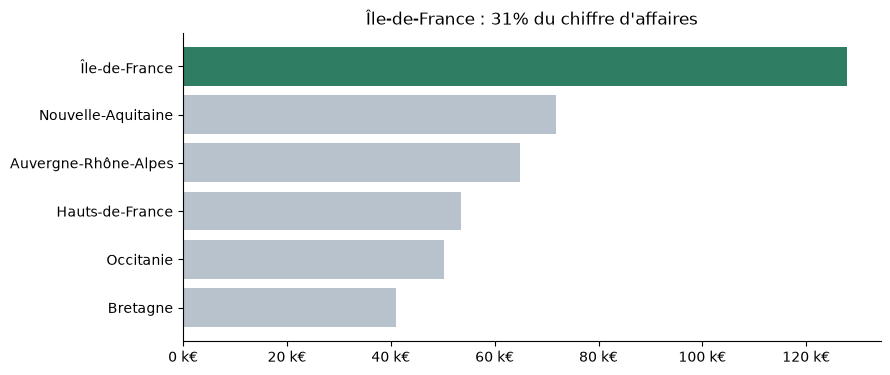

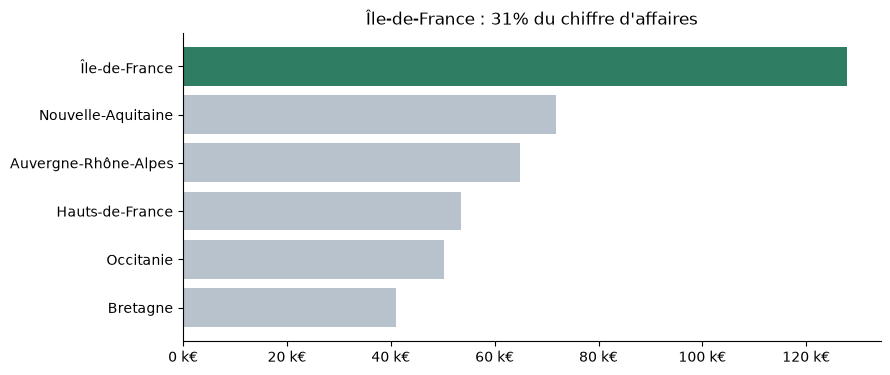

In [4]:
graphiques.ca_par_region(indicateurs)

L'Île-de-France réalise 31 % du chiffre d'affaires, près du double de la Nouvelle-Aquitaine, deuxième région.

## 4. Des objectifs qui ignorent la saisonnalité

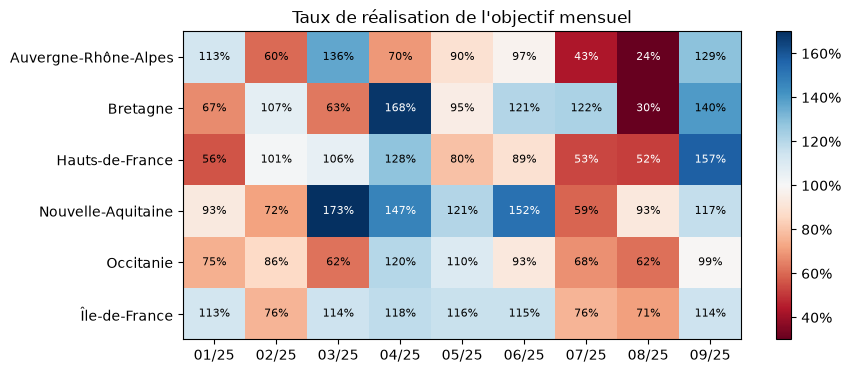

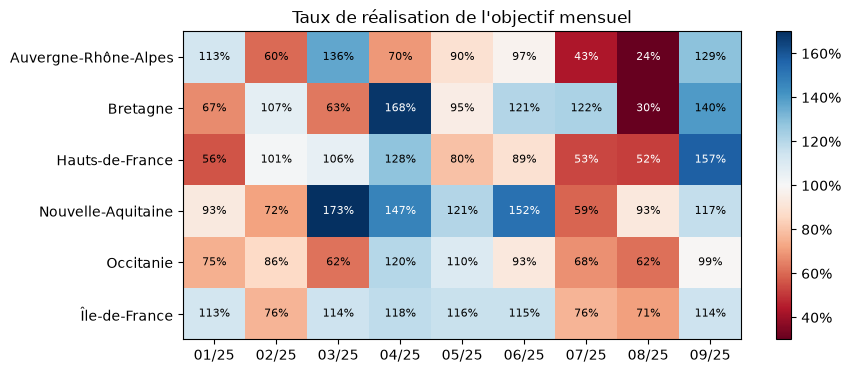

In [5]:
graphiques.taux_realisation(indicateurs)

In [6]:
(indicateurs["taux_realisation"] >= 1).groupby(indicateurs["region"]).sum().sort_values(ascending=False)

region
Île-de-France           6
Bretagne                5
Nouvelle-Aquitaine      5
Hauts-de-France         4
Auvergne-Rhône-Alpes    3
Occitanie               2
Name: taux_realisation, dtype: int64

L'Île-de-France atteint son objectif 6 mois sur 9, l'Occitanie seulement 2. En juillet et août, presque toutes les régions sont en dessous : les objectifs mensuels, identiques toute l'année, ne tiennent pas compte de la saisonnalité.

## 5. Ce qui fait le chiffre d'affaires

In [7]:
par_categorie = df.groupby("categorie").agg(ca=("montant", "sum"), quantite=("quantite", "sum"))
par_categorie["part_ca"] = par_categorie["ca"] / par_categorie["ca"].sum()
par_categorie.sort_values("ca", ascending=False).round(2)

,ca,quantite,part_ca
categorie,,,
Informatique,185274.68,2424,0.45
Bureau,124548.45,1235,0.30
Papeterie,59180.80,7225,0.14
Électroménager,37824.04,777,0.09
Non référencé,2673.62,50,0.01


L'informatique pèse 45 % du chiffre d'affaires. La papeterie est de loin la première catégorie en quantité, mais ne représente que 14 % du chiffre d'affaires. 17 ventes concernent un produit absent du catalogue (P17), à régulariser.

## Conclusions

1. Construire des objectifs mensuels saisonnalisés, à partir de l'historique, plutôt qu'un objectif fixe.
2. Suivre de près l'Occitanie et l'Auvergne-Rhône-Alpes, les plus irrégulières.
3. Compléter le catalogue avec le produit P17, vendu depuis août.

Le rapport HTML complet se génère avec `uv run rapport-ventes` à la racine du projet.